In [5]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sb
import pygsheets
from hashlib import sha256
import numpy as np
import plotly.graph_objects as go

Cache file: 360b78a208b44b7dd4226d3124a643581b2c2a69315c295c7fed223fc9a243b2
Using cached Google Sheets data.
🗑 Removed 22 ticker(s): ['NGXCG', 'NGXASEM', 'NGXBNK', 'NGXPENSION', 'NGXGROWTH', 'NGXPREMIUM', 'NGXINS', 'NGXOILGAS', 'NGXCNSMRGDS', 'NGXINDUSTR', 'NGXCOMMDTY', 'NGXSOVBND', 'NGXLOTUSISLM', 'MERGROwth', 'VSPBONDETF', 'VETGOODS', 'VETGRIF30', 'SIAMLETF40', 'VETINDETF', 'ASI', 'NGX30', 'NGX50']
Remaining tickers: 129  → ['ABCTRANS', 'ACADEMY', 'ACCESSCORP', 'AFRINSURE', 'AFRIPRUD', 'AFROMEDIA', 'AIRTELAFRI', 'AIICO', 'ARADEL', 'AUSTINLAZ', 'AVACAP', 'BERGER', 'BUACEMENT', 'BUAFOODS', 'CAP', 'CAVERTON', 'CHAMPION', 'CHAMS', 'CHELLARAM', 'CILEASING', 'CONHALLPLC', 'CONOIL', 'CUSTODIAN', 'CUTIX', 'CWG', 'DAARCOMM', 'DANGCEM', 'DANGSUGAR', 'CMFC', 'DUNLOP', 'EKOCORP', 'ENAMELWA', 'ETI', 'ETRANZACT', 'EUNISELL', 'FCMB', 'FIDELITYBK', 'FTGINSURE', 'FTNCOCOA', 'FLOURMILL', 'GEREGU', 'GTCO', 'GUINNESS', 'HMCALL', 'HONYFLOUR', 'INTBREW', 'INTENEGINS', 'JAIZBANK', 'JBERGER', 'JOHNHOLT', '

C:\Users\Segun\AppData\Local\Temp\ipykernel_22772\1935122399.py:114: FutureWarning:

The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.

C:\Users\Segun\anaconda3\Lib\site-packages\seaborn\matrix.py:560: UserWarning:

Clustering large matrix with scipy. Installing `fastcluster` may give better performance.

C:\Users\Segun\anaconda3\Lib\site-packages\seaborn\matrix.py:560: UserWarning:

Clustering large matrix with scipy. Installing `fastcluster` may give better performance.



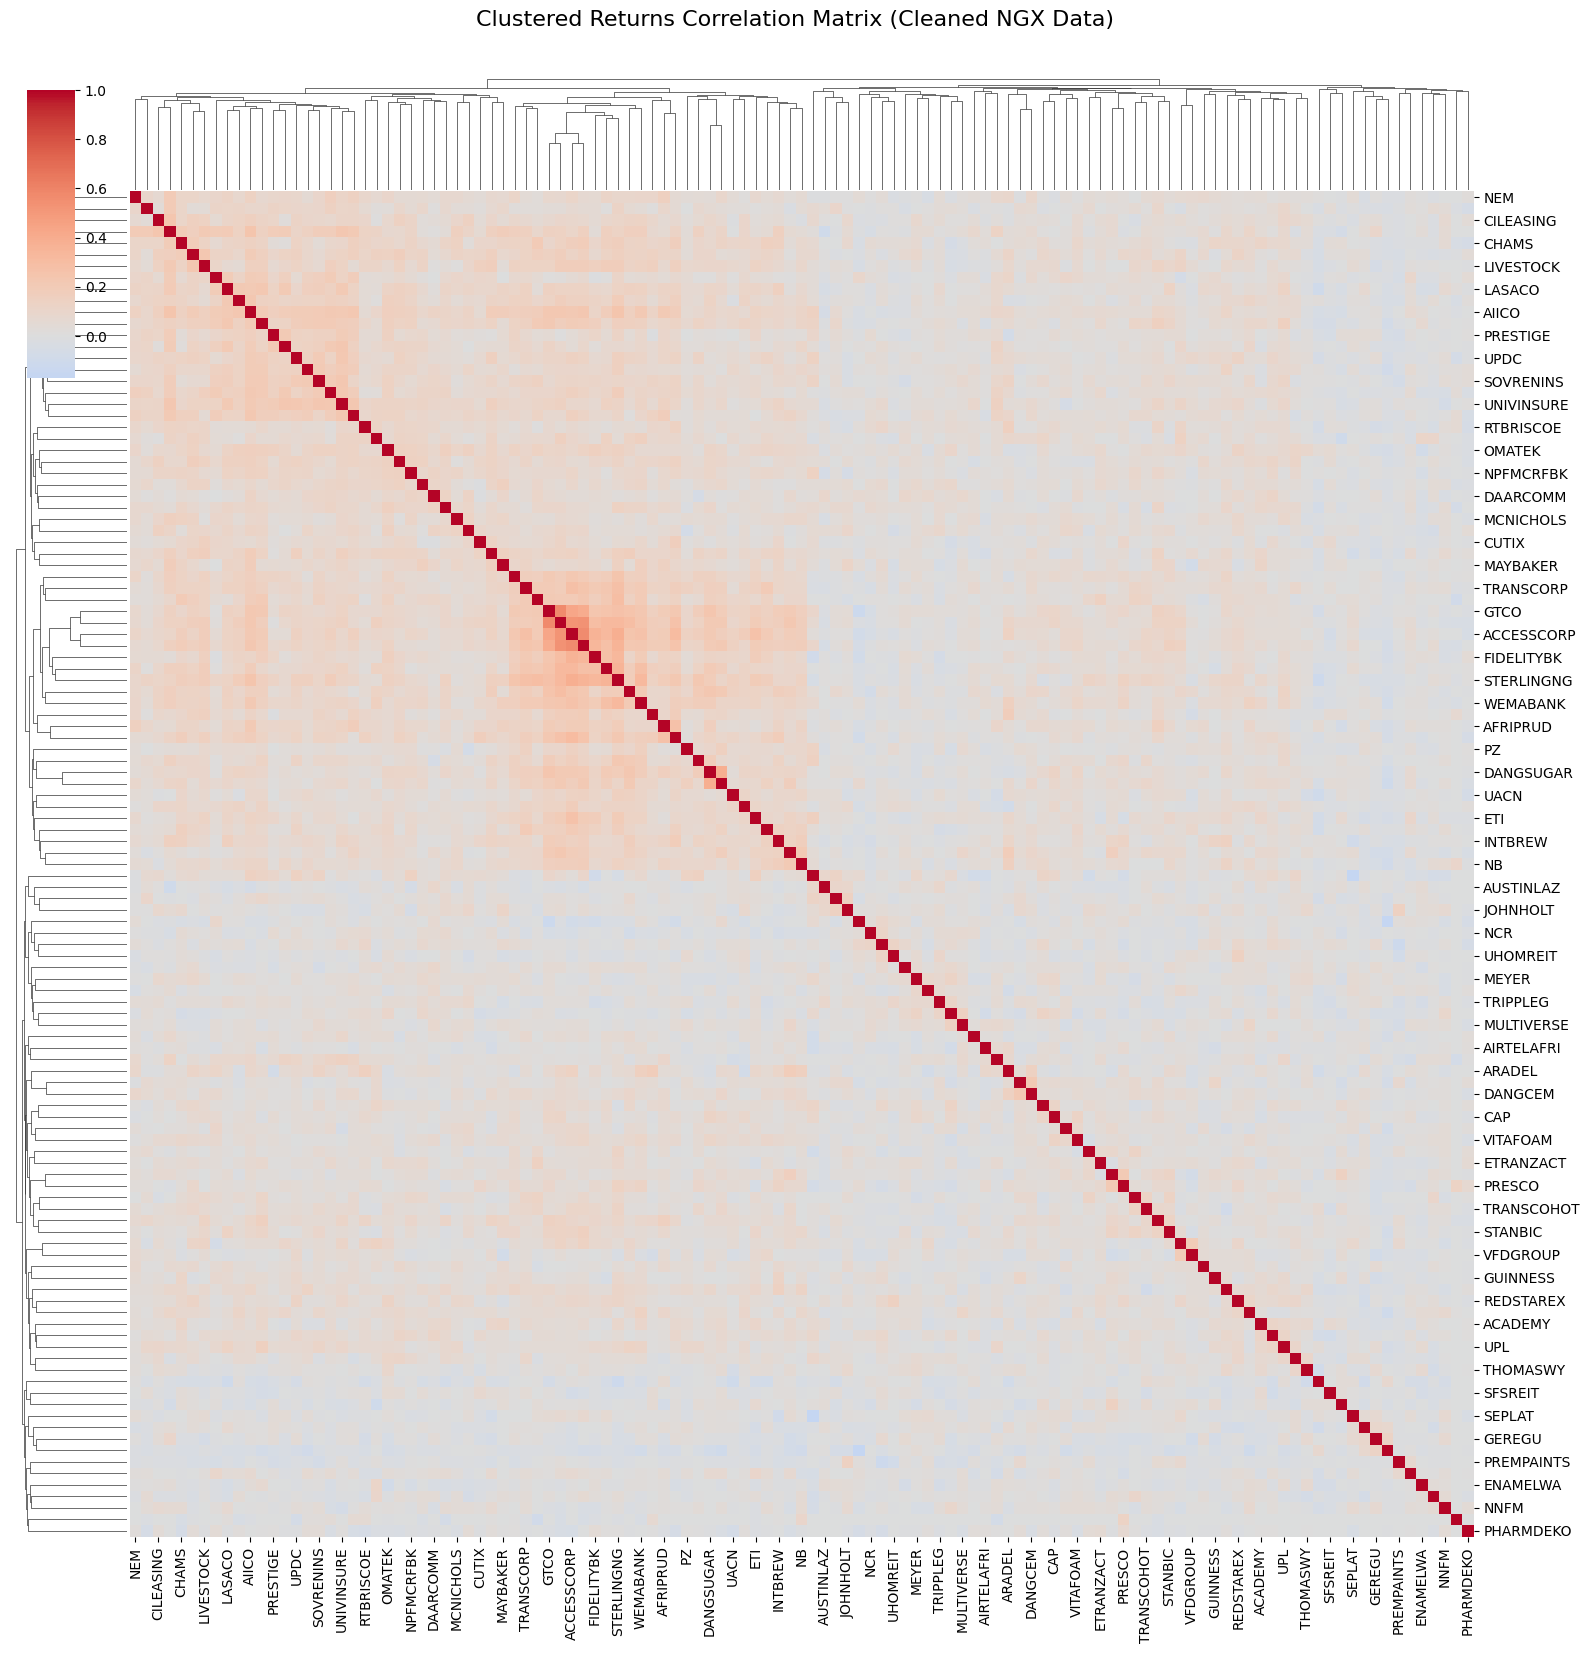

In [10]:
# =====================================================
# CONFIG
# =====================================================

SERVICE_ACCOUNT_FILE = r"C:\Users\Segun\Desktop\wqu-satellite-image-learning1-175e0a0906aa.json"
SHEET_URL = "https://docs.google.com/spreadsheets/d/1jkbrrHnR48JztVz0SrqZELKjOenVm44wsiIchLW0K9g/edit"
WORKSHEET_INDEX = 1
DATE_COL = "datetime"

START_DATE = "2022-01-01"
END_DATE = "2026-09-17"

# =====================================================
# CACHE FILE (DATE-AWARE)
# =====================================================

unique_filename = sha256(
    f"{SHEET_URL}{WORKSHEET_INDEX}{START_DATE}{END_DATE}".encode()
).hexdigest()

print(f"Cache file: {unique_filename}")

# =====================================================
# GOOGLE SHEET DATA RETRIEVER
# =====================================================

class GoogleSheetStockDataRetriever:
    def __init__(
        self,
        service_account_file,
        sheet_url,
        worksheet_index,
        date_col="datetime",
        start_date=None,
        end_date=None,
    ):
        self.service_account_file = service_account_file
        self.sheet_url = sheet_url
        self.worksheet_index = worksheet_index
        self.date_col = date_col
        self.start_date = start_date
        self.end_date = end_date

    def fetch_data(self):
        gc = pygsheets.authorize(
            service_account_file=self.service_account_file
        )

        sh = gc.open_by_url(self.sheet_url)
        wks = sh[self.worksheet_index]

        df = wks.get_as_df()

        # Parse date column
        df[self.date_col] = pd.to_datetime(df[self.date_col])
        df = df.set_index(self.date_col)

        # Convert ALL columns to numeric safely
        df = df.apply(pd.to_numeric, errors="coerce")

        # Filter date range
        if self.start_date:
            df = df[df.index >= pd.to_datetime(self.start_date)]
        if self.end_date:
            df = df[df.index <= pd.to_datetime(self.end_date)]

        # Drop empty columns
        df = df.dropna(axis=1, how="all")

        return df

# =====================================================
# LOAD OR FETCH DATA
# =====================================================

try:
    coll = pd.read_pickle(unique_filename)
    print("Using cached Google Sheets data.")
except FileNotFoundError:
    print("Cache not found. Fetching from Google Sheets...")

    retriever = GoogleSheetStockDataRetriever(
        service_account_file=SERVICE_ACCOUNT_FILE,
        sheet_url=SHEET_URL,
        worksheet_index=WORKSHEET_INDEX,
        date_col=DATE_COL,
        start_date=START_DATE,
        end_date=END_DATE,
    )

    coll = retriever.fetch_data()
    coll.to_pickle(unique_filename)

# =====================================================
# TICKER FILTER  ← edit this list to drop any tickers
# =====================================================
REMOVE_TICKERS = ['NGXCG', 'NGXASEM', 'NGXBNK', 'NGXPENSION', 'NGXGROWTH', 'NGXPREMIUM', 'NGXINS', 
                  'NGXOILGAS', 'NGXCNSMRGDS', 'NGXINDUSTR', 'NGXCOMMDTY', 'NGXSOVBND', 'NGXLOTUSISLM','MERGROwth', 
                  'VSPBONDETF', 'VETGOODS', 'VETGRIF30', 'SIAMLETF40', 'VETINDETF', 'ASI', 'NGX30', 'NGX50']  

cols_to_drop = [c for c in REMOVE_TICKERS if c in coll.columns]
if cols_to_drop:
    coll = coll.drop(columns=cols_to_drop)
    print(f"🗑 Removed {len(cols_to_drop)} ticker(s): {cols_to_drop}")
else:
    print("ℹ No tickers removed (none matched columns).")

print(f"Remaining tickers: {coll.shape[1]}  → {list(coll.columns)}")

# =====================================================
# COMPUTE DAILY RETURNS
# =====================================================
 
returns = coll.pct_change().dropna(how="all")

# =====================================================
# CLUSTERED CORRELATION (ROBUST FIX)
# =====================================================

# Remove columns with too many missing values (need at least 30% of rows)
min_obs = int(0.3 * len(returns))
returns_clean = returns.dropna(axis=1, thresh=min_obs)
 
# Drop zero-variance columns
returns_clean = returns_clean.loc[:, returns_clean.std() > 0]
 
print(f"\nClean returns shape (after dropping sparse/zero-var cols): {returns_clean.shape}")
 
# Correlation matrix
returns_corr = returns_clean.corr()
 
# Replace NaN / inf safely
returns_corr = returns_corr.replace([float("inf"), -float("inf")], pd.NA)
returns_corr = returns_corr.fillna(0)
 
# Ensure diagonal is exactly 1
for col in returns_corr.columns:
    returns_corr.loc[col, col] = 1.0
 
# Clustered heatmap
sb.clustermap(
    returns_corr,
    cmap="coolwarm",
    center=0,
    figsize=(16, 16),
    linewidths=0,
    dendrogram_ratio=(0.08, 0.08),
    cbar_pos=(0.02, 0.8, 0.03, 0.18)
)
 
plt.suptitle(
    "Clustered Returns Correlation Matrix (Cleaned NGX Data)",
    fontsize=16,
    y=1.03
)
 
plt.show()

C:\Users\Segun\AppData\Local\Temp\ipykernel_22772\3275522648.py:7: FutureWarning:

The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.



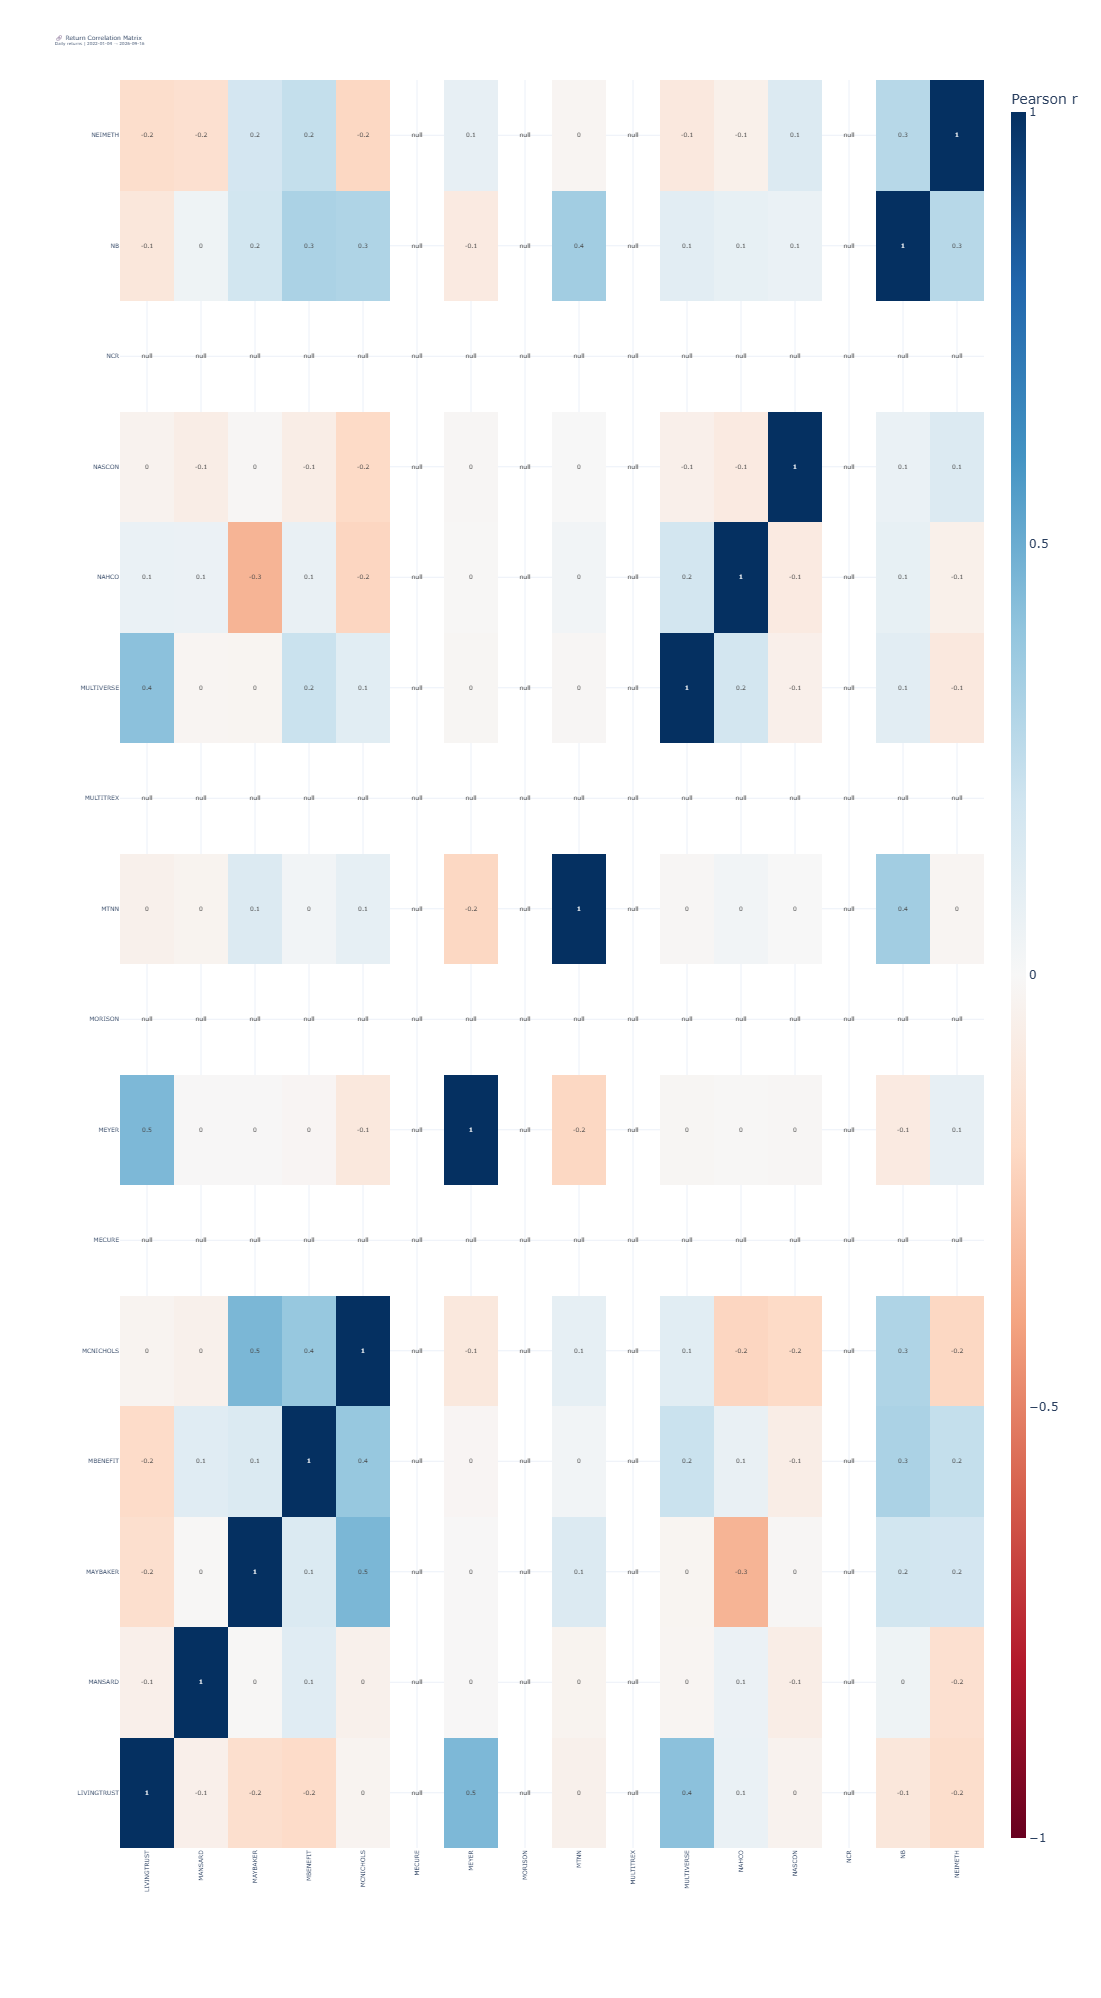

In [25]:

# =====================================================
# PLOT 2: Correlation Matrix (on daily returns)
# =====================================================
# Compute on returns, not prices — price correlation is often
# spurious due to shared trend; return correlation is more meaningful

daily_returns = coll.pct_change().dropna()
corr = daily_returns.corr()

# ── Heatmap
fig2 = go.Figure(go.Heatmap(
    z=corr.values,
    x=corr.columns.tolist(),
    y=corr.index.tolist(),
    colorscale="RdBu",
    zmid=0,              # centre colour scale at zero
    zmin=-1, zmax=1,
    text=corr.round(1).values,
    texttemplate="%{text}",
    textfont=dict(size=6),
    hovertemplate="<b>%{y} vs %{x}</b><br>Correlation: %{z:.4f}<extra></extra>",
    colorbar=dict(title="Pearson r", thickness=15)
))


fig2.update_layout(
    title=dict(
        text="🔗 Return Correlation Matrix<br>"
             f"<sup>Daily returns | {coll.index.min().date()} → {coll.index.max().date()}</sup>",
        font=dict(size=6)
    ),
    template="plotly_white",
    height=max(800, 450 + len(corr) * 12),
    width=1200,
    xaxis=dict(
        side="bottom",
        tickfont=dict(size=6),
        tickangle= -90
    ),
    yaxis=dict(
        tickfont=dict(size=6),
        automargin=True
    ),
    margin=dict(l=120, r=100, t=80, b=150)
)

fig2.show()